# CS 6220 Homework 4


## Part 1 Frequent Itemsets


In [1]:
from itertools import combinations

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"],
]

In [2]:
def support(candidate_itemset, transactions):
    """Fraction of transactions that contain every item in candidate_itemset."""
    candidate = frozenset(candidate_itemset)
    count = sum(1 for t in transactions if candidate.issubset(t))
    return count / len(transactions)


def confidence(antecedent, consequent, transactions):
    """Confidence of the rule antecedent -> consequent:
    support(antecedent ∪ consequent) / support(antecedent)."""
    both = set(antecedent) | set(consequent)
    return support(both, transactions) / support(antecedent, transactions)

In [3]:
def join_step(freq_prev, k):
    """Join frequent (k-1)-itemsets into length-k candidates.
    Itemsets are sorted tuples. Two itemsets are joined only if they share
    the same first k-2 items, which avoids generating duplicates."""
    candidates = []
    for i in range(len(freq_prev)):
        for j in range(i + 1, len(freq_prev)):
            a, b = freq_prev[i], freq_prev[j]
            if a[:k - 2] == b[:k - 2]:
                candidates.append(a + (b[-1],))
    return candidates


def prune_step(candidates, freq_prev):
    """Split candidates into (kept, pruned). A candidate is pruned if any of
    its (k-1)-subsets is not in the frequent (k-1)-itemsets."""
    freq_prev_set = set(freq_prev)
    kept, pruned = [], []
    for c in candidates:
        if all(sub in freq_prev_set for sub in combinations(c, len(c) - 1)):
            kept.append(c)
        else:
            pruned.append(c)
    return kept, pruned

In [4]:
def apriori(transactions, min_sup):
    """Return (frequent, log).
    frequent: {k: {itemset_tuple: support}}
    log:      {k: info about the join/prune/count steps for level k}"""
    items = sorted({item for t in transactions for item in t})

    # k = 1: count every single item
    L = [(item,) for item in items if support((item,), transactions) >= min_sup]
    frequent = {1: {c: support(c, transactions) for c in L}}
    log = {}

    k = 2
    while L:
        candidates = join_step(L, k)                    # 1. join
        kept, pruned = prune_step(candidates, L)        # 2. prune
        L = [c for c in kept
             if support(c, transactions) >= min_sup]    # 3. count
        log[k] = {"joined": len(candidates), "pruned": pruned,
                  "counted": len(kept), "frequent": len(L)}
        if L:
            frequent[k] = {c: support(c, transactions) for c in L}
        k += 1
    return frequent, log


frequent, log = apriori(transactions, min_sup=0.25)

for k, itemsets in frequent.items():
    print(f"Frequent {k}-itemsets ({len(itemsets)}):")
    for itemset, sup in itemsets.items():
        print(f"   {itemset}  support = {sup:.2f}")

print()
for k, info in log.items():
    print(f"k={k}: {info['joined']} candidates joined, "
          f"{len(info['pruned'])} pruned {info['pruned']}, "
          f"{info['counted']} counted, {info['frequent']} frequent")

Frequent 1-itemsets (5):
   ('Bread',)  support = 0.40
   ('Butter',)  support = 0.30
   ('Cereal',)  support = 0.25
   ('Eggs',)  support = 0.30
   ('Milk',)  support = 0.55
Frequent 2-itemsets (4):
   ('Bread', 'Butter')  support = 0.30
   ('Bread', 'Eggs')  support = 0.25
   ('Bread', 'Milk')  support = 0.25
   ('Butter', 'Milk')  support = 0.25
Frequent 3-itemsets (1):
   ('Bread', 'Butter', 'Milk')  support = 0.25

k=2: 10 candidates joined, 0 pruned [], 10 counted, 4 frequent
k=3: 3 candidates joined, 2 pruned [('Bread', 'Butter', 'Eggs'), ('Bread', 'Eggs', 'Milk')], 1 counted, 1 frequent
k=4: 0 candidates joined, 0 pruned [], 0 counted, 0 frequent


## Part 2 Association Rules


In [5]:
EPS = 1e-9  # tolerance so float rounding can't wrongly reject a borderline confidence


def apriori_rules(itemset, transactions, min_conf):
    """Find all rules X -> Y with X ∪ Y = itemset and confidence >= min_conf.

    Anti-monotonicity: if X -> Y fails min_conf, then moving more items from X
    into Y can only lower confidence. So we grow the consequent Y level by level:
      join  : combine passing consequents of size m-1 into candidates of size m
      prune : drop a candidate if any (m-1)-subset was not a passing consequent
      count : compute confidence for survivors, keep those >= min_conf
    Returns (rules, log)."""
    itemset = tuple(sorted(itemset))
    rules, log = [], {}

    def count_step(candidate_consequents):
        passing = []
        for y in candidate_consequents:
            x = tuple(i for i in itemset if i not in y)
            conf = confidence(x, y, transactions)
            if conf >= min_conf - EPS:
                passing.append(y)
                rules.append({
                    "antecedent": x,
                    "consequent": y,
                    "support": support(itemset, transactions),
                    "confidence": conf,
                    "lift": conf / support(y, transactions),
                })
        return passing

    # m = 1: every single-item consequent is a starting candidate
    singles = [(item,) for item in itemset]
    passing = count_step(singles)
    log[1] = {"joined": len(singles), "pruned": [],
              "counted": len(singles), "passed": len(passing)}

    # m >= 2: grow consequents; the antecedent must stay non-empty (m < len(itemset))
    m = 2
    while passing and m < len(itemset):
        candidates = join_step(passing, m)               # 1. join
        kept, pruned = prune_step(candidates, passing)   # 2. prune
        passing = count_step(kept)                       # 3. count
        log[m] = {"joined": len(candidates), "pruned": pruned,
                  "counted": len(kept), "passed": len(passing)}
        m += 1
    return rules, log

In [6]:
all_rules = []
for k, itemsets in frequent.items():
    if k < 2:
        continue  # a rule needs at least 2 items
    for itemset in itemsets:
        rules, rule_log = apriori_rules(itemset, transactions, min_conf=0.6)
        all_rules.extend(rules)
        for m, info in rule_log.items():
            print(f"{itemset}, consequent size {m}: {info['joined']} joined, "
                  f"{len(info['pruned'])} pruned, {info['counted']} counted, "
                  f"{info['passed']} passed")

print(f"\n{len(all_rules)} rules with confidence >= 0.6\n")
print(f"{'Rule':45} {'Support':>8} {'Conf':>7} {'Lift':>7}")
for r in sorted(all_rules, key=lambda r: -r["confidence"]):
    rule_str = f"{set(r['antecedent'])} -> {set(r['consequent'])}"
    print(f"{rule_str:45} {r['support']:8.2f} {r['confidence']:7.3f} {r['lift']:7.3f}")

('Bread', 'Butter'), consequent size 1: 2 joined, 0 pruned, 2 counted, 2 passed
('Bread', 'Eggs'), consequent size 1: 2 joined, 0 pruned, 2 counted, 2 passed
('Bread', 'Milk'), consequent size 1: 2 joined, 0 pruned, 2 counted, 1 passed
('Butter', 'Milk'), consequent size 1: 2 joined, 0 pruned, 2 counted, 1 passed
('Bread', 'Butter', 'Milk'), consequent size 1: 3 joined, 0 pruned, 3 counted, 3 passed
('Bread', 'Butter', 'Milk'), consequent size 2: 3 joined, 0 pruned, 3 counted, 2 passed

11 rules with confidence >= 0.6

Rule                                           Support    Conf    Lift
{'Butter'} -> {'Bread'}                           0.30   1.000   2.500
{'Milk', 'Butter'} -> {'Bread'}                   0.25   1.000   2.500
{'Milk', 'Bread'} -> {'Butter'}                   0.25   1.000   3.333
{'Eggs'} -> {'Bread'}                             0.25   0.833   2.083
{'Butter'} -> {'Milk'}                            0.25   0.833   1.515
{'Bread', 'Butter'} -> {'Milk'}                  

## Part 3 Hierarchical Clustering


Number of points: 370


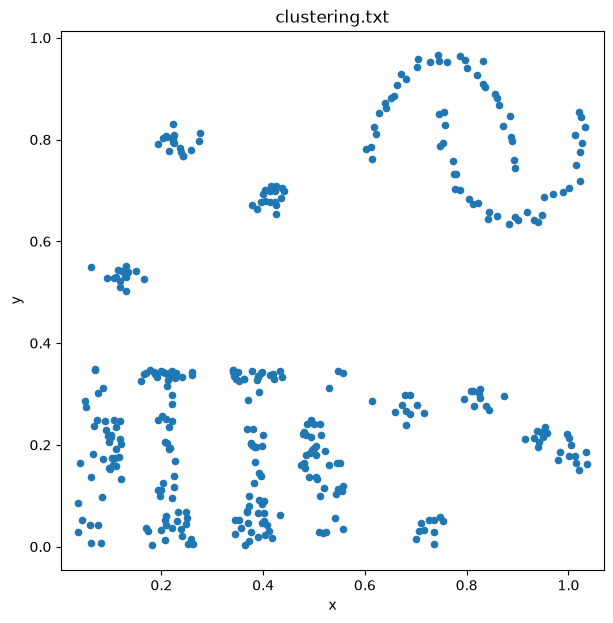

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

points = np.loadtxt("data/clustering.txt", delimiter=",")
print("Number of points:", len(points))

plt.figure(figsize=(7, 7))
plt.scatter(points[:, 0], points[:, 1], s=20)
plt.title("clustering.txt")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

In [8]:
# Cluster distance functions. After merging clusters A and B, the distance from
# any other cluster C to the new cluster is computed from d(C,A) and d(C,B) alone:
#   min_dist: d(C, A∪B) = min(d(C,A), d(C,B))   (single link)
#   max_dist: d(C, A∪B) = max(d(C,A), d(C,B))   (complete link)
# Each takes the two distance rows (one entry per other cluster) and returns the new row.
min_dist = np.minimum
max_dist = np.maximum


def hac(points, cluster_dist):
    """Hierarchical agglomerative clustering.

    cluster_dist: min_dist or max_dist (rule for updating distances after a merge).
    Returns Z, an (n-1) x 4 array in the same format SciPy uses, one row per merge:
      [id of cluster 1, id of cluster 2, distance at merge, size of new cluster].
    Points have ids 0..n-1; the cluster created at merge step s gets id n+s."""
    n = len(points)

    # Pairwise Euclidean distances between individual points (the only time
    # distances are computed from the raw points).
    diff = points[:, None, :] - points[None, :, :]
    D = np.sqrt((diff ** 2).sum(axis=2))
    np.fill_diagonal(D, np.inf)      # a cluster is never merged with itself

    ids = list(range(n))             # cluster id currently stored in each matrix row
    sizes = [1] * n                  # number of points in each cluster
    Z = []

    for step in range(n - 1):
        # 1. Find the closest pair of active clusters
        i, j = np.unravel_index(np.argmin(D), D.shape)
        if i > j:
            i, j = j, i

        # 2. Record the merge for the dendrogram
        Z.append([ids[i], ids[j], D[i, j], sizes[i] + sizes[j]])

        # 3. Incremental update: row i becomes the merged cluster, computed from
        #    the old rows i and j. No point-to-point distances are recomputed.
        new_row = cluster_dist(D[i], D[j])
        D[i, :] = new_row
        D[:, i] = new_row
        D[i, i] = np.inf

        # 4. Retire row/column j (infinite distance so it is never selected again)
        D[j, :] = np.inf
        D[:, j] = np.inf

        ids[i] = n + step
        sizes[i] += sizes[j]

    return np.array(Z)


def get_clusters(Z, n, k):
    """Cluster label (0..k-1) for every point when the dendrogram is cut into k
    clusters: replay the first n-k merges using union-find."""
    parent = list(range(2 * n - 1))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for step in range(n - k):
        a, b = int(Z[step, 0]), int(Z[step, 1])
        parent[find(a)] = n + step
        parent[find(b)] = n + step

    roots = [find(i) for i in range(n)]
    label_of_root = {r: c for c, r in enumerate(dict.fromkeys(roots))}
    return np.array([label_of_root[r] for r in roots])

In [9]:
def run_and_plot(points, cluster_dist, name, k=13):
    """Run HAC, plot the dendrogram, then plot the points colored by cluster."""
    n = len(points)
    Z = hac(points, cluster_dist)
    labels = get_clusters(Z, n, k)

    # Height of the cut that leaves k clusters (between merge n-k-1 and merge n-k)
    cut = (Z[n - k - 1, 2] + Z[n - k, 2]) / 2

    fig, ax = plt.subplots(figsize=(12, 4))
    dendrogram(Z, no_labels=True, color_threshold=cut, ax=ax)
    ax.axhline(cut, color="k", linestyle="--", linewidth=1)
    ax.set_title(f"Dendrogram ({name}), dashed line = cut for {k} clusters")
    ax.set_ylabel("cluster distance")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab20", s=25)
    ax.set_title(f"{k} clusters ({name})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.axis("equal")
    plt.show()

    print("Cluster sizes:", sorted(np.bincount(labels)))
    return Z, labels

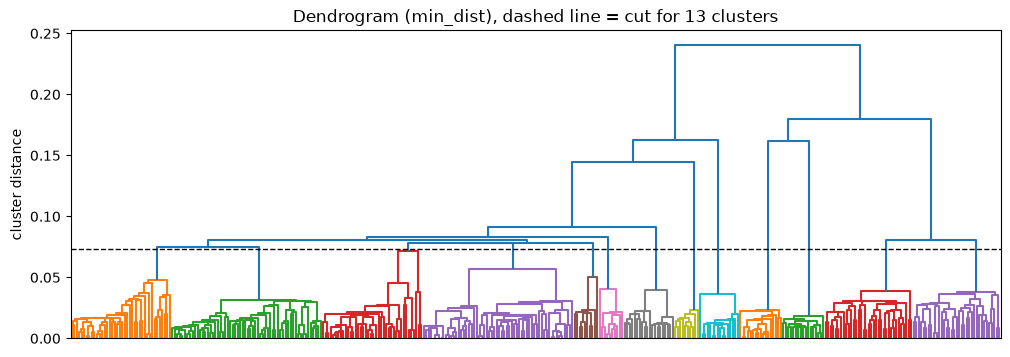

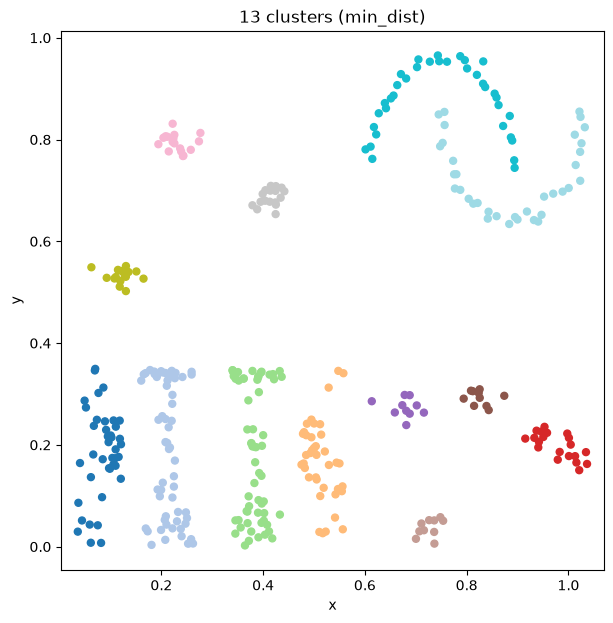

Cluster sizes: [np.int64(10), np.int64(10), np.int64(10), np.int64(16), np.int64(17), np.int64(17), np.int64(20), np.int64(35), np.int64(35), np.int64(40), np.int64(40), np.int64(60), np.int64(60)]


In [10]:
Z_min, labels_min = run_and_plot(points, min_dist, "min_dist")

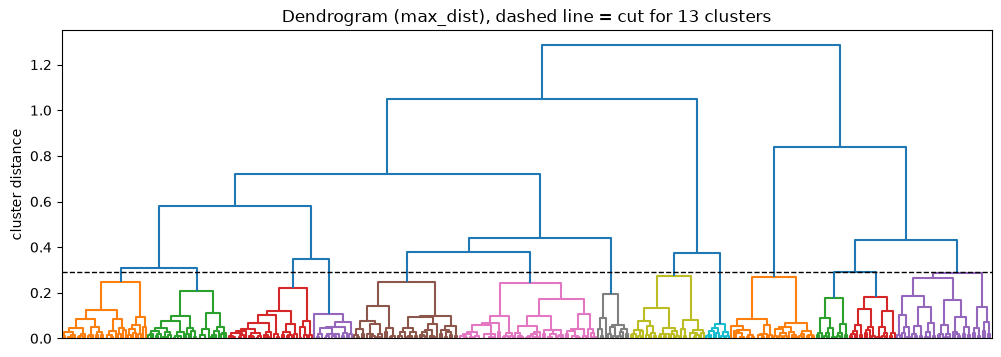

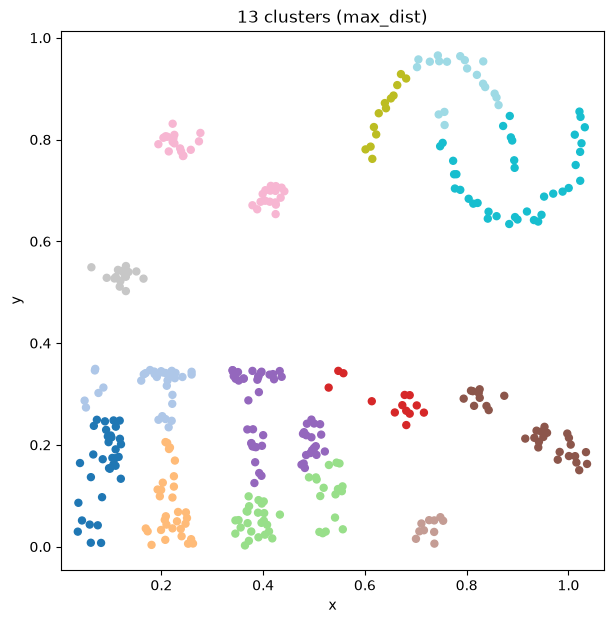

Cluster sizes: [np.int64(10), np.int64(13), np.int64(13), np.int64(16), np.int64(19), np.int64(30), np.int64(32), np.int64(34), np.int64(34), np.int64(34), np.int64(38), np.int64(42), np.int64(55)]


In [11]:
Z_max, labels_max = run_and_plot(points, max_dist, "max_dist")

In [12]:
from scipy.cluster.hierarchy import linkage

for name, Z, method in [("min", Z_min, "single"), ("max", Z_max, "complete")]:
    print(name, "matches SciPy:",
          np.allclose(np.sort(Z[:, 2]), np.sort(linkage(points, method=method)[:, 2])))

min matches SciPy: True
max matches SciPy: True
